In [250]:
! pip install xgboost

In [325]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.stats import chi2_contingency
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.cluster import KMeans

In [252]:
df1 = pd.read_csv(r'C:\Users\maria\OneDrive\Documentos\data-science-projects\projeto-1-previsao-vendas\dados\car_purchasing.csv', encoding='latin1')

In [253]:
df1.head()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248


# **Objetivo**
Desenvolver um modelo de regressão que preveja o valor de compra de um carro (car purchase amount) com base em dados demográficos e financeiros do cliente.

Esse modelo será útil para:

- Prever o ticket médio de novos clientes.

- Auxiliar estratégias de marketing personalizado.

- Segmentar clientes com maior probabilidade de alto investimento.

Utilizaremos Regressão para prever o ticket médio de preços
- Modelo: Supervisionado
- XGBRegressor 
- Variável alvo: Purchase Amount 

E para clusterização de cliente: 
- Modelo: Não Supervisionado
- KMeans
- Agrupar clientes em perfis semelhantes com base em variáveis como:
- Idade
- Gênero
- Tempo como cliente
- Valor total gasto
- Frequência de compra
- Canal de aquisição




## **Etapa do Projeto - CRISP DM**

## **Dicionário de Dados**
- customer_name: Nome do cliente
- customer_e_mail: Endereço de e-mail
- county: País de origem do cliente
- gender: Gênero do Cliente 
- age: Idade do cliente
- credit card debt: Valor da dívida atual no cartão 
- net worth: Patrimônio líquido
- car purchase amount: Valor de compra do carro

# **Análise Inicial**

In [254]:
# verificando número de linhas
df1.shape

(500, 9)

In [255]:
# verificando informações gerais
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   customer name        500 non-null    object 
 1   customer e-mail      500 non-null    object 
 2   country              500 non-null    object 
 3   gender               500 non-null    int64  
 4   age                  500 non-null    float64
 5   annual Salary        500 non-null    float64
 6   credit card debt     500 non-null    float64
 7   net worth            500 non-null    float64
 8   car purchase amount  500 non-null    float64
dtypes: float64(5), int64(1), object(3)
memory usage: 35.3+ KB


In [256]:
# verificando dados nulos
df1.isnull().sum()

customer name          0
customer e-mail        0
country                0
gender                 0
age                    0
annual Salary          0
credit card debt       0
net worth              0
car purchase amount    0
dtype: int64

In [257]:
df1.dtypes

customer name           object
customer e-mail         object
country                 object
gender                   int64
age                    float64
annual Salary          float64
credit card debt       float64
net worth              float64
car purchase amount    float64
dtype: object

# **Resumo**
- 500 linhas x 9 colunas
- Formato de dados adequados
- Sem valores nulos
- Variável alvo: Regressão -> Prever o ticket médio
- Variável alvo: Clusterlização -> Identificar perfis de compradores que gastam mais

# **Análise bivariada de dados categóricos**
- Gênero
- País
- Car Purchase Amount: O valor monetário que um cliente gastou na compra de um veículo.

In [258]:
df1.head()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248


## **Agrupando faixas**

In [259]:
df1['car purchase amount'].describe()

count      500.000000
mean     44209.799218
std      10773.178744
min       9000.000000
25%      37629.896040
50%      43997.783390
75%      51254.709517
max      80000.000000
Name: car purchase amount, dtype: float64

In [260]:
bins = [0, 20000, 30000, 40000, 50000, 60000, 80000]
labels = ['Até 20k', '20k-30k', '30k-40k', '40k-50k', '50k-60k', 'Acima de 60k']

In [261]:
df1['faixa_compra'] = pd.cut(df1['car purchase amount'], bins=bins, labels=labels)

In [262]:

df1.head()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount,faixa_compra
0,Martina Avila,cubilia.Curae.Phasellus@quisaccumsanconvallis.edu,Bulgaria,0,41.851720,62812.09301,11609.380910,238961.2505,35321.45877,30k-40k
1,Harlan Barnes,eu.dolor@diam.co.uk,Belize,0,40.870623,66646.89292,9572.957136,530973.9078,45115.52566,40k-50k
2,Naomi Rodriquez,vulputate.mauris.sagittis@ametconsectetueradip...,Algeria,1,43.152897,53798.55112,11160.355060,638467.1773,42925.70921,40k-50k
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313,Acima de 60k
4,Cedric Leach,felis.ullamcorper.viverra@egetmollislectus.net,Brazil,1,57.313749,59729.15130,5358.712177,560304.0671,55915.46248,50k-60k


In [263]:
df1.tail()

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount,faixa_compra
495,Walter,ligula@Cumsociis.ca,Nepal,0,41.462515,71942.40291,6995.902524,541670.1016,48901.44342,40k-50k
496,Vanna,Cum.sociis.natoque@Sedmolestie.edu,Zimbabwe,1,37.642000,56039.49793,12301.456790,360419.0988,31491.41457,30k-40k
497,Pearl,penatibus.et@massanonante.com,Philippines,1,53.943497,68888.77805,10611.606860,764531.3203,64147.28888,Acima de 60k
498,Nell,Quisque.varius@arcuVivamussit.net,Botswana,1,59.160509,49811.99062,14013.034510,337826.6382,45442.15353,40k-50k
499,Marla,Camaron.marla@hotmail.com,marlal,1,46.731152,61370.67766,9391.341628,462946.4924,45107.22566,40k-50k


## **Análise de Gênero**

In [264]:
df1['genero'] = df1['gender'].map({0: 'Homem', 1: 'Mulher'})

c:\Users\maria\anaconda3\Lib\site-packages\seaborn\categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


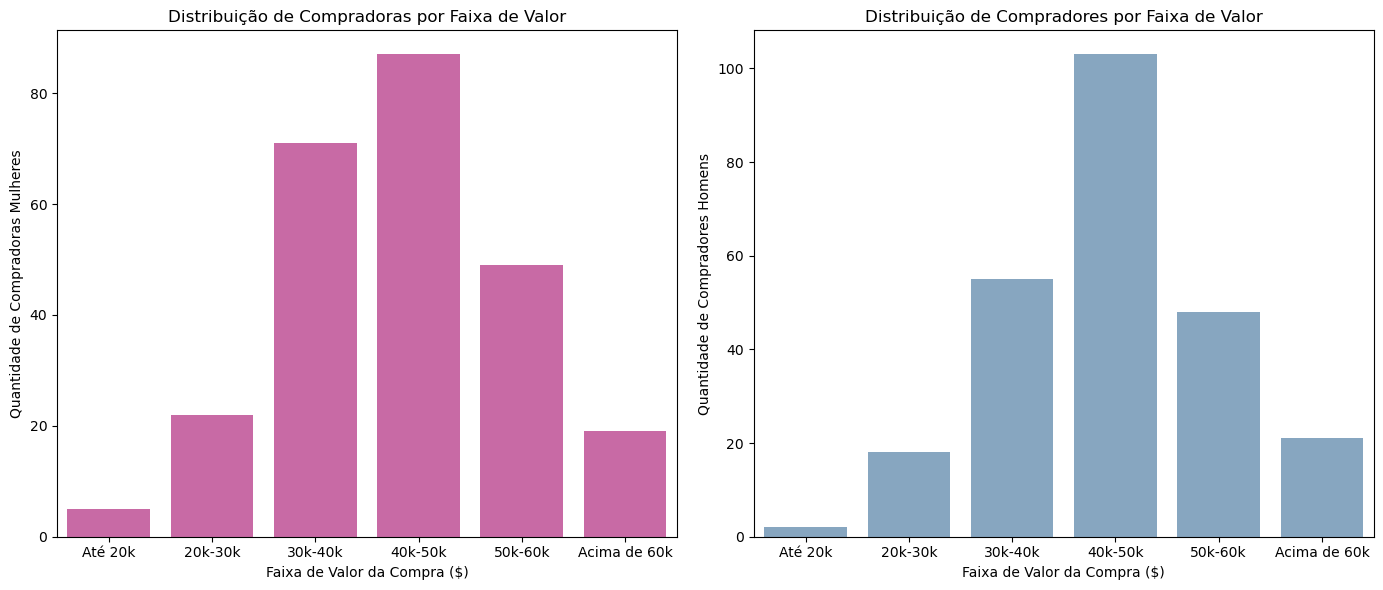

In [265]:
plt.figure(figsize=(14, 6))

# Gráfico para Mulheres
plt.subplot(1, 2, 1)
sns.countplot(data=df1[df1['genero'] == 'Mulher'], x='faixa_compra', color='mediumvioletred', alpha=0.7)
plt.title('Distribuição de Compradoras por Faixa de Valor')
plt.xlabel('Faixa de Valor da Compra ($)')
plt.ylabel('Quantidade de Compradoras Mulheres')
plt.xticks(rotation=0)

# Gráfico para Homens
plt.subplot(1, 2, 2)
sns.countplot(data=df1[df1['genero'] == 'Homem'], x='faixa_compra', color='steelblue', alpha=0.7)
plt.title('Distribuição de Compradores por Faixa de Valor')
plt.xlabel('Faixa de Valor da Compra ($)')
plt.ylabel('Quantidade de Compradores Homens')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

- Temos uma maior concentração mulheres que fizeram compras de 40k-50k
- E o mesmo padrão se repete para Homens

In [266]:
df1['genero'].value_counts(normalize=True).round(2)

genero
Mulher    0.51
Homem     0.49
Name: proportion, dtype: float64

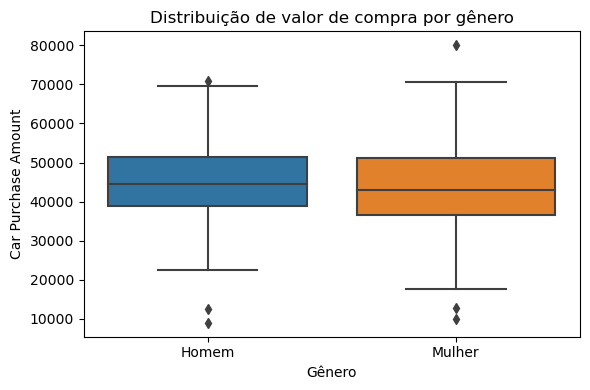

In [267]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df1, x='genero', y='car purchase amount')
plt.title('Distribuição de valor de compra por gênero')
plt.xticks([0, 1], ['Homem', 'Mulher'])
plt.xlabel('Gênero')
plt.ylabel('Car Purchase Amount')
plt.tight_layout()
plt.show()

- Teste de Hipótese:Existe diferença estatisticamente significativa entre os gêneros na distribuição das faixas de valor de compra

- Utilizei o teste do qui-quadrado de independência por serem 2 valores de análise categóricos

In [268]:
tabela = pd.crosstab(
    df1['faixa_compra'],
    df1['genero']
)

In [269]:
tabela

genero,Homem,Mulher
faixa_compra,,
Até 20k,2,5
20k-30k,18,22
30k-40k,55,71
40k-50k,103,87
50k-60k,48,49
Acima de 60k,21,19


In [270]:
chi2, p, dof, expected = chi2_contingency(tabela)

In [271]:
print("Estatística do Qui-Quadrado", chi2)
print("Graus de Liberadade", dof)
print("Valor-p", p)

Estatística do Qui-Quadrado 5.103872974571804
Graus de Liberadade 5
Valor-p 0.403335474586078


In [272]:
if p < 0.05:
    print("➡ Existe diferença significativa entre os gêneros nas faixas de compra.")
else:
    print("➡ Não há diferença estatisticamente significativa entre os gêneros nas faixas de compra.")

➡ Não há diferença estatisticamente significativa entre os gêneros nas faixas de compra.


Valor-p < 0.05: Rejeitamos a hipótese nula → existe associação entre gênero e faixa de compra.

Valor-p ≥ 0.05: Não rejeitamos a hipótese nula → não existe associação significativa.



## **Análise por País**

In [273]:
pd.set_option('display.max_rows', None)

In [274]:
df1['country'].value_counts()

country
Israel                                          6
Mauritania                                      6
Bolivia                                         6
Greenland                                       5
Saint Barthélemy                                5
Guinea                                          5
Iraq                                            5
Samoa                                           5
Liechtenstein                                   5
Bhutan                                          5
Kyrgyzstan                                      5
Equatorial Guinea                               5
Algeria                                         5
Laos                                            5
Grenada                                         5
Armenia                                         5
Saint Vincent and The Grenadines                4
Senegal                                         4
Saint Pierre and Miquelon                       4
Marshall Islands                          

In [275]:
country_to_continent = {
    'Israel': 'Asia',
    'Mauritania': 'Africa',
    'Bolivia': 'South America',
    'Greenland': 'North America',
    'Saint Barthélemy': 'North America',
    'Guinea': 'Africa',
    'Iraq': 'Asia',
    'Samoa': 'Oceania',
    'Liechtenstein': 'Europe',
    'Bhutan': 'Asia',
    'Kyrgyzstan': 'Asia',
    'Equatorial Guinea': 'Africa',
    'Algeria': 'Africa',
    'Laos': 'Asia',
    'Grenada': 'North America',
    'Armenia': 'Asia',
    'Saint Vincent and The Grenadines': 'North America',
    'Senegal': 'Africa',
    'Saint Pierre and Miquelon': 'North America',
    'Marshall Islands': 'Oceania',
    'Venezuela': 'South America',
    'Sierra Leone': 'Africa',
    'Namibia': 'Africa',
    'Guam': 'Oceania',
    'Egypt': 'Africa',
    'Andorra': 'Europe',
    'Madagascar': 'Africa',
    'French Polynesia': 'Oceania',
    'Saint Kitts and Nevis': 'North America',
    'Sao Tome and Principe': 'Africa',
    'Puerto Rico': 'North America',
    'China': 'Asia',
    'Jersey': 'Europe',
    'Mauritius': 'Africa',
    'Gambia': 'Africa',
    'United States Minor Outlying Islands': 'Oceania',
    'Kiribati': 'Oceania',
    'Ecuador': 'South America',
    'Poland': 'Europe',
    'Slovakia': 'Europe',
    'Congo (Brazzaville)': 'Africa',
    'Mayotte': 'Africa',
    'Macao': 'Asia',
    'Croatia': 'Europe',
    'Uganda': 'Africa',
    'Kuwait': 'Asia',
    'Bouvet Island': 'Antarctica',
    'Wallis and Futuna': 'Oceania',
    'South Africa': 'Africa',
    'Guadeloupe': 'North America',
    'Martinique': 'North America',
    'Latvia': 'Europe',
    'Maldives': 'Asia',
    'Belize': 'North America',
    'Christmas Island': 'Oceania',
    'Falkland Islands': 'South America',
    'Solomon Islands': 'Oceania',
    'Yemen': 'Asia',
    'Nepal': 'Asia',
    'Cocos (Keeling) Islands': 'Oceania',
    'Northern Mariana Islands': 'Oceania',
    'Tuvalu': 'Oceania',
    'Iceland': 'Europe',
    'Viet Nam': 'Asia',
    'Portugal': 'Europe',
    'Turkey': 'Europe',
    'Suriname': 'South America',
    'Dominican Republic': 'North America',
    'Isle of Man': 'Europe',
    'Colombia': 'South America',
    'Macedonia': 'Europe',
    'Tokelau': 'Oceania',
    'Mozambique': 'Africa',
    'Micronesia': 'Oceania',
    'United Arab Emirates': 'Asia',
    'Palestine, State of': 'Asia',
    'Chile': 'South America',
    'Uruguay': 'South America',
    'Brazil': 'South America',
    'Turkmenistan': 'Asia',
    'Costa Rica': 'North America',
    'Jamaica': 'North America',
    'Cape Verde': 'Africa',
    'Timor-Leste': 'Asia',
    'Djibouti': 'Africa',
    'Turks and Caicos Islands': 'North America',
    'Åland Islands': 'Europe',
    'Benin': 'Africa',
    'Belarus': 'Europe',
    'Thailand': 'Asia',
    'Norfolk Island': 'Oceania',
    'Bermuda': 'North America',
    'Guernsey': 'Europe',
    'Bahamas': 'North America',
    'Afghanistan': 'Asia',
    'United States': 'North America',
    'Bangladesh': 'Asia',
    'Antarctica': 'Antarctica',
    'Korea, South': 'Asia',
    'Luxembourg': 'Europe',
    'Greece': 'Europe',
    'Malawi': 'Africa',
    'Zimbabwe': 'Africa',
    'Italy': 'Europe',
    'Niue': 'Oceania',
    'Western Sahara': 'Africa',
    'Saint Martin': 'North America',
    'Faroe Islands': 'Europe',
    'Haiti': 'North America',
    'Guatemala': 'North America',
    'Malta': 'Europe',
    'Papua New Guinea': 'Oceania',
    'Canada': 'North America',
    'Lithuania': 'Europe',
    'Morocco': 'Africa',
    'French Southern Territories': 'Antarctica',
    'Philippines': 'Asia',
    'Virgin Islands, British': 'North America',
    'Heard Island and Mcdonald Islands': 'Antarctica',
    'Bosnia and Herzegovina': 'Europe',
    'India': 'Asia',
    'Curaçao': 'North America',
    'Bulgaria': 'Europe',
    'Austria': 'Europe',
    'Ghana': 'Africa',
    'Anguilla': 'North America',
    'Angola': 'Africa',
    'Syria': 'Asia',
    'Paraguay': 'South America',
    'Slovenia': 'Europe',
    'Czech Republic': 'Europe',
    'Guinea-Bissau': 'Africa',
    'Mongolia': 'Asia',
    'Vanuatu': 'Oceania',
    'Somalia': 'Africa',
    'Argentina': 'South America',
    'Sint Maarten': 'North America',
    'French Guiana': 'South America',
    'Ethiopia': 'Africa',
    'France': 'Europe',
    'Botswana': 'Africa',
    'Nigeria': 'Africa',
    'Indonesia': 'Asia',
    'Jordan': 'Asia',
    'Tunisia': 'Africa',
    'Pakistan': 'Asia',
    'Myanmar': 'Asia',
    'Liberia': 'Africa',
    'Qatar': 'Asia',
    'Serbia': 'Europe',
    'Bahrain': 'Asia',
    'San Marino': 'Europe',
    'Seychelles': 'Africa',
    'Nicaragua': 'North America',
    'Switzerland': 'Europe',
    'Malaysia': 'Asia',
    'Montenegro': 'Europe',
    'United Kingdom (Great Britain)': 'Europe',
    'Saint Helena, Ascension and Tristan da Cunha': 'Africa',
    'Gabon': 'Africa',
    'Chad': 'Africa',
    'Sudan': 'Africa',
    'American Samoa': 'Oceania',
    'New Zealand': 'Oceania',
    'South Georgia and The South Sandwich Islands': 'Antarctica',
    'Australia': 'Oceania',
    'Ukraine': 'Europe',
    'South Sudan': 'Africa',
    'Cook Islands': 'Oceania',
    'Belgium': 'Europe',
    'Mali': 'Africa',
    'New Caledonia': 'Oceania',
    'Niger': 'Africa',
    'Hungary': 'Europe',
    'Cayman Islands': 'North America',
    'Honduras': 'North America',
    'Mexico': 'North America',
    'Rwanda': 'Africa',
    'Tonga': 'Oceania',
    'Tanzania': 'Africa',
    'Moldova': 'Europe',
    'Kenya': 'Africa',
    'Monaco': 'Europe',
    'Lebanon': 'Asia',
    'Aruba': 'North America',
    'Hong Kong': 'Asia',
    'Japan': 'Asia',
    'Saint Lucia': 'North America',
    'Saudi Arabia': 'Asia',
    'Singapore': 'Asia',
    'Togo': 'Africa',
    'Central African Republic': 'Africa',
    'Cameroon': 'Africa',
    'Guyana': 'South America',
    'Palau': 'Oceania',
    'Kazakhstan': 'Asia',
    'Reunion': 'Africa',
    'Germany': 'Europe',
    'Virgin Islands, United States': 'North America',
    'Sri Lanka': 'Asia',
    'Taiwan': 'Asia',
    'Nauru': 'Oceania',
    'Georgia': 'Europe',
    'Cambodia': 'Asia',
    'Peru': 'South America',
    'Bonaire, Sint Eustatius and Saba': 'North America',
    'El Salvador': 'North America',
    'Denmark': 'Europe',
    'Oman': 'Asia',
    'Trinidad and Tobago': 'North America',
    'marlal': 'Unknown'

}

In [276]:
df1['continent'] = df1['country'].map(country_to_continent).fillna('Unknown')

In [277]:
df1['continent'].value_counts()

continent
Africa           116
Asia             103
Europe            85
North America     83
Oceania           63
South America     39
Antarctica        10
Unknown            1
Name: count, dtype: int64

In [278]:
df1[df1['continent'] == 'Unknown']

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount,faixa_compra,genero,continent
499,Marla,Camaron.marla@hotmail.com,marlal,1,46.731152,61370.67766,9391.341628,462946.4924,45107.22566,40k-50k,Mulher,Unknown


<function matplotlib.pyplot.tight_layout(*, pad=1.08, h_pad=None, w_pad=None, rect=None)>

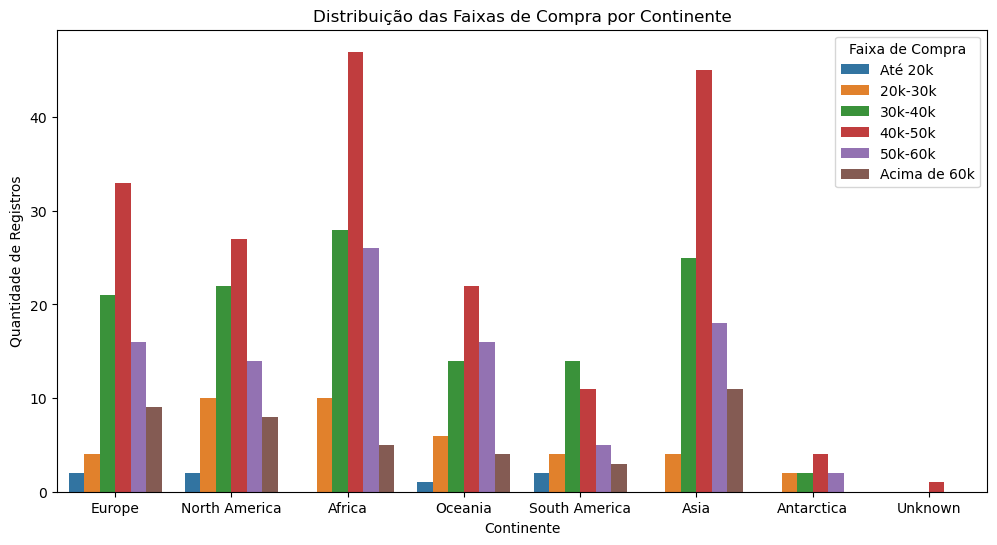

In [279]:
plt.figure(figsize=(12,6))
sns.countplot(data=df1, x='continent', hue='faixa_compra')

plt.title('Distribuição das Faixas de Compra por Continente')
plt.xlabel('Continente')
plt.ylabel('Quantidade de Registros')
plt.legend(title='Faixa de Compra')
plt.tight_layout

In [280]:
tabela_continente = pd.crosstab(
    df1['faixa_compra'],
    df1['continent'],
    margins=True
    
)

In [281]:
tabela_continente

continent,Africa,Antarctica,Asia,Europe,North America,Oceania,South America,Unknown,All
faixa_compra,,,,,,,,,
Até 20k,0,0,0,2,2,1,2,0,7
20k-30k,10,2,4,4,10,6,4,0,40
30k-40k,28,2,25,21,22,14,14,0,126
40k-50k,47,4,45,33,27,22,11,1,190
50k-60k,26,2,18,16,14,16,5,0,97
Acima de 60k,5,0,11,9,8,4,3,0,40
All,116,10,103,85,83,63,39,1,500


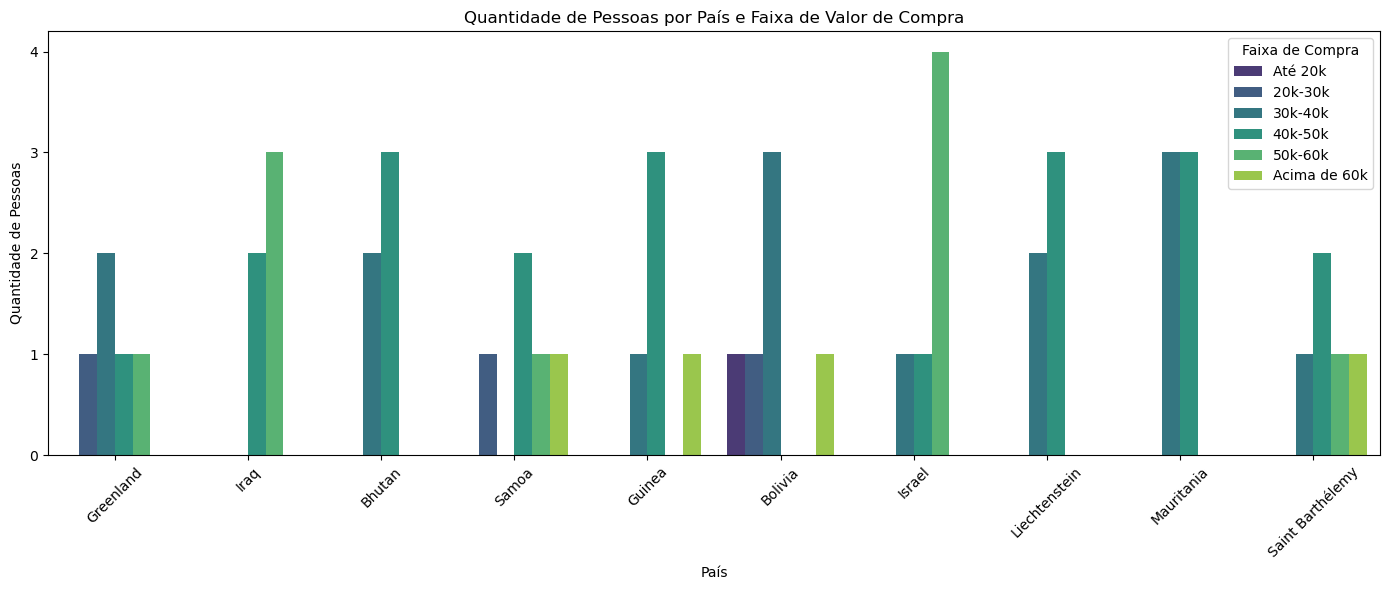

In [282]:
plt.figure(figsize=(14, 6))
ax = sns.countplot(data=df_top, x='country', hue='faixa_compra', palette='viridis')

# Define o eixo Y para exibir apenas inteiros
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))

plt.title('Quantidade de Pessoas por País e Faixa de Valor de Compra')
plt.xlabel('País')
plt.ylabel('Quantidade de Pessoas')
plt.xticks(rotation=45)
plt.legend(title='Faixa de Compra')
plt.tight_layout()
plt.show()

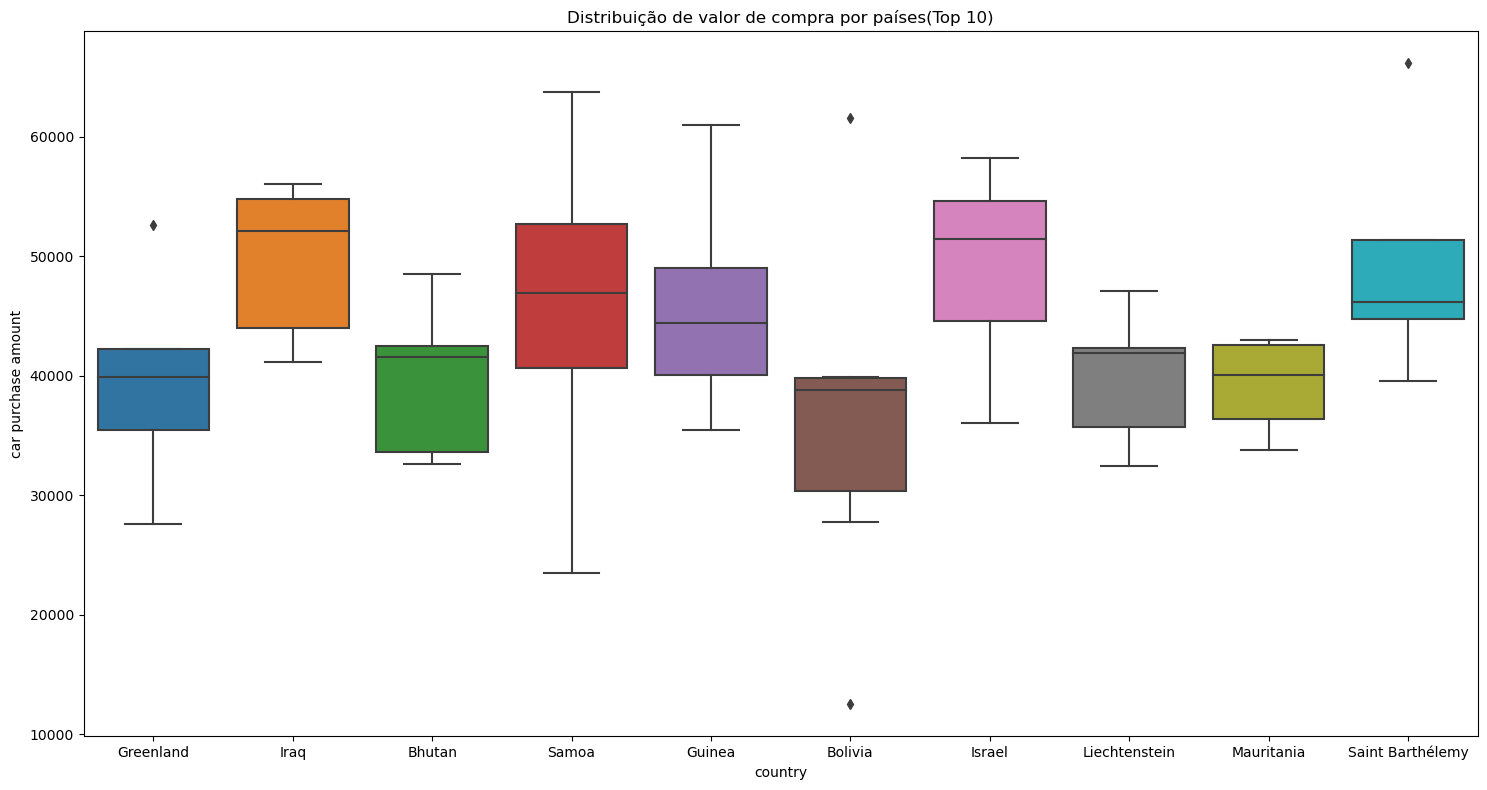

In [283]:
# Selecionar os 5 países mais frequentes
top_paises = df1['country'].value_counts().nlargest(10).index
df_top = df1[df1['country'].isin(top_paises)]

plt.figure(figsize=(15, 8))
sns.boxplot(data=df_top, x='country', y='car purchase amount')
plt.title('Distribuição de valor de compra por países(Top 10)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## **Análise de variáveis numéricas**

In [284]:
def plot_histograma(df, coluna, bins=30, cor='darkorange'):
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x=coluna, bins=bins, kde=False, color=cor, alpha=0.8)
    plt.title(f'Distribuição da Variável: {coluna}', fontsize=14)
    plt.xlabel(coluna, fontsize=12)
    plt.ylabel('Quantidade de Registros', fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()
    plt.show()

In [285]:
def plotar_histogramas_numericos(df, bins=30, cor='darkorange'):
    colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns
    for coluna in colunas_numericas:
        plot_histograma(df, coluna, bins=bins, cor=cor)

c:\Users\maria\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


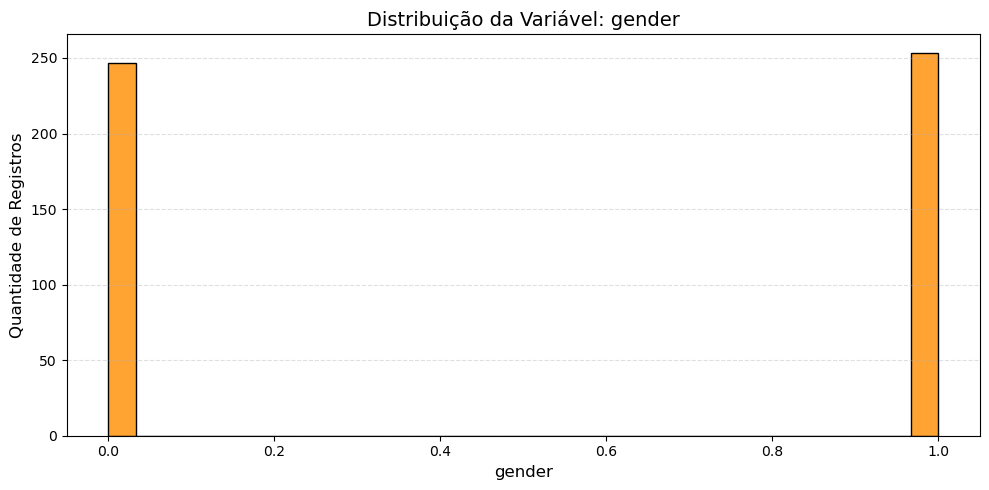

c:\Users\maria\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


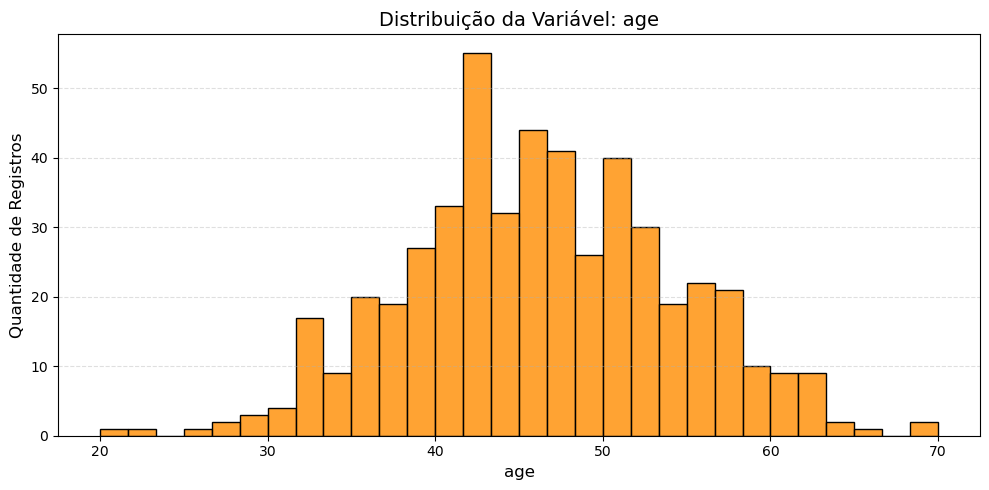

c:\Users\maria\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


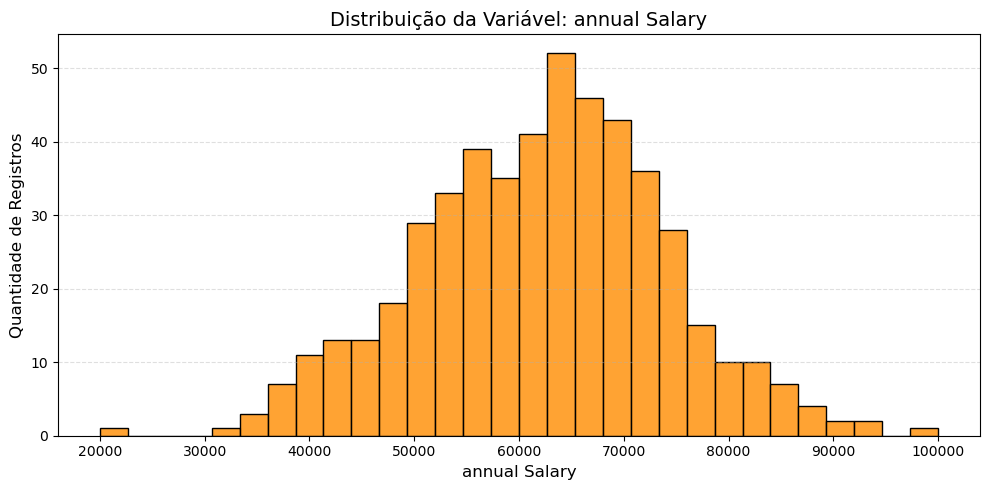

c:\Users\maria\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


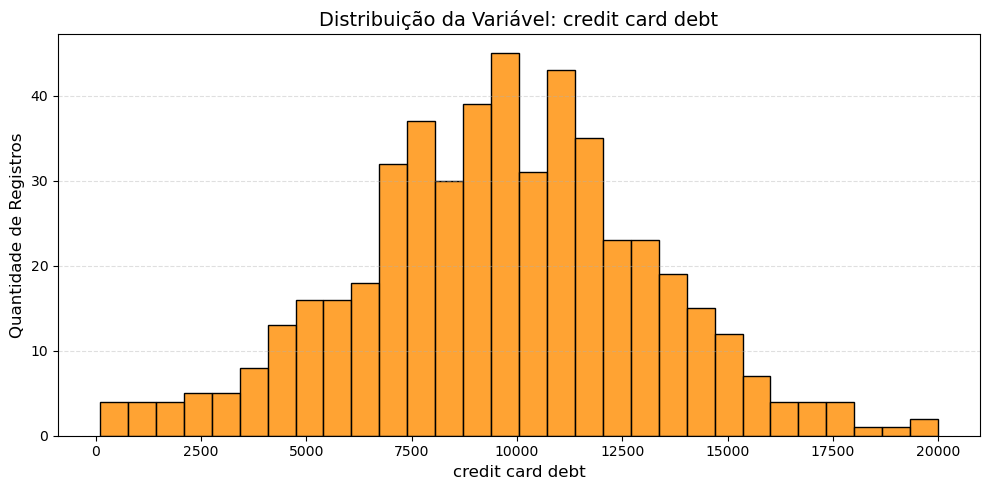

c:\Users\maria\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


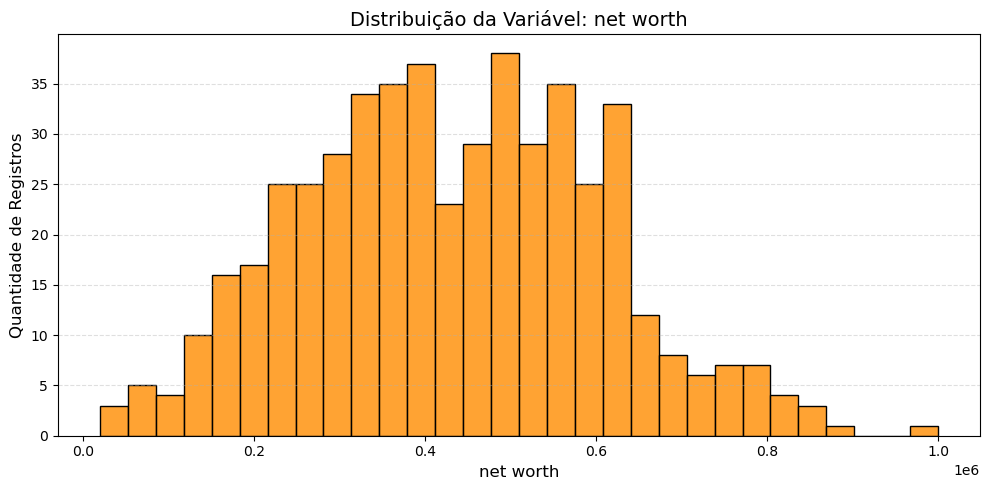

c:\Users\maria\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.


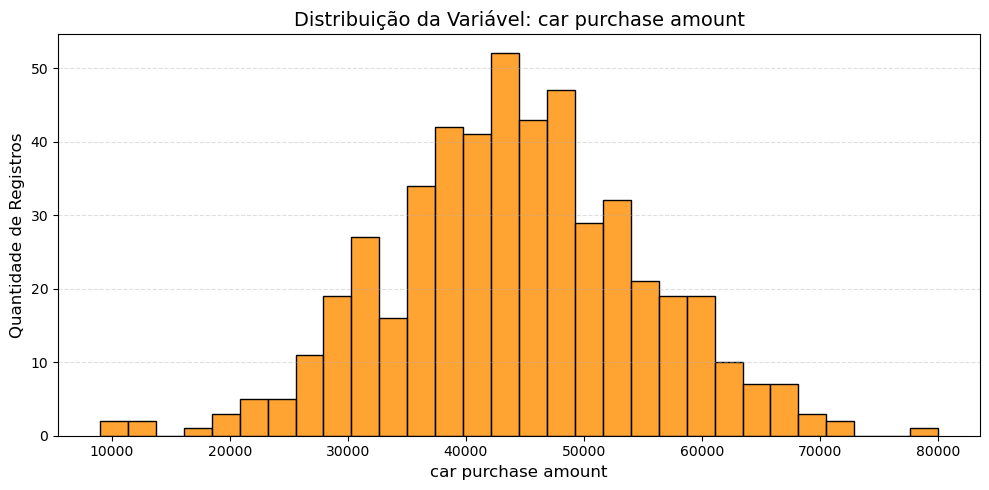

In [286]:
plotar_histogramas_numericos(df1)

## **Engenharia de requisitos**

In [287]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   customer name        500 non-null    object  
 1   customer e-mail      500 non-null    object  
 2   country              500 non-null    object  
 3   gender               500 non-null    int64   
 4   age                  500 non-null    float64 
 5   annual Salary        500 non-null    float64 
 6   credit card debt     500 non-null    float64 
 7   net worth            500 non-null    float64 
 8   car purchase amount  500 non-null    float64 
 9   faixa_compra         500 non-null    category
 10  genero               500 non-null    object  
 11  continent            500 non-null    object  
dtypes: category(1), float64(5), int64(1), object(5)
memory usage: 43.8+ KB


## Renda dispnivel

In [288]:
df1['renda_disponivel'] = df1['annual Salary'] - df1['credit card debt']
df1[['customer name','annual Salary', 'credit card debt', 'faixa_compra', 'renda_disponivel' ]].head(10)

,customer name,annual Salary,credit card debt,faixa_compra,renda_disponivel
0,Martina Avila,62812.09301,11609.380910,30k-40k,51202.712100
1,Harlan Barnes,66646.89292,9572.957136,40k-50k,57073.935784
2,Naomi Rodriquez,53798.55112,11160.355060,40k-50k,42638.196060
3,Jade Cunningham,79370.03798,14426.164850,Acima de 60k,64943.873130
4,Cedric Leach,59729.15130,5358.712177,50k-60k,54370.439123
5,Carla Hester,68499.85162,14179.472440,50k-60k,54320.379180
6,Griffin Rivera,39814.52200,5958.460188,20k-30k,33856.061812
7,Orli Casey,51752.23445,10985.696560,40k-50k,40766.537890
8,Marny Obrien,58139.25910,3440.823799,40k-50k,54698.435301
9,Rhonda Chavez,53457.10132,12884.078680,30k-40k,40573.022640


## **Proporção dívida**

In [289]:
df1['proporcao_divida'] = df1['credit card debt'] / df1['annual Salary']

## Patrimonio liquido

In [290]:
df1['patrimonio_liquido'] = df1['net worth'] - df1['credit card debt']


## Faixa etária 

In [291]:
df1['age'].describe()

count    500.000000
mean      46.241674
std        7.978862
min       20.000000
25%       40.949969
50%       46.049901
75%       51.612263
max       70.000000
Name: age, dtype: float64

In [292]:
df1['faixa_etaria'] = pd.cut(df1['age'], bins=[18, 30, 50, 100], labels=['jovem', 'adulto', 'sênior'])

## Faixa Salarial

In [293]:
df1['faixa_salarial'] = pd.cut(df1['annual Salary'], bins=[0, 50000, 100000, 150000, 300000], labels=['baixa', 'média', 'alta', 'premium'])


## Score de Marketing

In [294]:
scaler = MinMaxScaler()
df1[['age_scaled', 'salary_scaled', 'purchase_scaled']] = scaler.fit_transform(
    df1[['age', 'annual Salary', 'car purchase amount']]
)

In [295]:
df1['score_marketing_alvo'] = (
    (100 - df1['age']) * 0.3 + 
    (df1['annual Salary'] / df1['annual Salary'].max()) * 100 * 0.3 +
    (df1['car purchase amount'] / df1['car purchase amount'].max()) * 100 * 0.4
)
df1['score_marketing_alvo'] = df1['score_marketing_alvo'].round(2)

In [296]:
df1['faixa_compra'].value_counts()

faixa_compra
40k-50k         190
30k-40k         126
50k-60k          97
20k-30k          40
Acima de 60k     40
Até 20k           7
Name: count, dtype: int64

In [297]:
def classificar_engajamento(row):
    if row['faixa_compra'] in ['Acima de 60k', '50k-60k'] and row['annual Salary'] > 70000:
        return 'Alto'
    elif row['faixa_compra'] in ['40k-50k', '30k-40k'] and row['annual Salary'] > 50000:
        return 'Médio'
    else:
        return 'Baixo'


In [298]:
df1['engajamento_previsto'] = df1.apply(classificar_engajamento, axis=1)

In [299]:
print(df1[['score_marketing_alvo', 'engajamento_previsto']].head())

   score_marketing_alvo engajamento_previsto
0                 53.95                Médio
1                 60.29                Médio
2                 54.66                Médio
3                 70.04                 Alto
4                 58.68                Baixo


In [300]:
df1['engajamento_previsto'].value_counts()

engajamento_previsto
Médio    273
Baixo    158
Alto      69
Name: count, dtype: int64

In [301]:
df1[df1['engajamento_previsto'] == 'Alto']

,customer name,customer e-mail,country,gender,age,annual Salary,credit card debt,net worth,car purchase amount,faixa_compra,...,renda_disponivel,proporcao_divida,patrimonio_liquido,faixa_etaria,faixa_salarial,age_scaled,salary_scaled,purchase_scaled,score_marketing_alvo,engajamento_previsto
3,Jade Cunningham,malesuada@dignissim.com,Cook Islands,1,58.271369,79370.03798,14426.164850,548599.0524,67422.36313,Acima de 60k,...,64943.873130,0.181758,534172.887550,sênior,média,0.765427,0.742125,0.822850,70.04,Alto
10,Jerome Rowe,ipsum.cursus@dui.org,Sint Maarten,1,50.129923,73348.70745,8270.707359,612738.6171,59045.51309,50k-60k,...,65078.000091,0.112759,604467.909741,sênior,média,0.602598,0.666859,0.704866,66.49,Alto
28,Gemma Hendrix,lobortis@non.co.uk,Denmark,1,46.124036,100000.00000,17452.921790,188032.0778,58350.31809,50k-60k,...,82547.078210,0.174529,170579.156010,adulto,média,0.522481,1.000000,0.695075,75.34,Alto
32,Dahlia Cleveland,tincidunt.tempus@idsapien.co.uk,Saint Pierre and Miquelon,1,51.316714,82358.22683,8092.475103,655934.4666,66363.89316,Acima de 60k,...,74265.751727,0.098259,647841.991497,sênior,média,0.626334,0.779478,0.807942,72.49,Alto
39,Christopher Stevens,blandit.enim@lacusvariuset.org,French Guiana,1,48.047296,80959.53310,4499.921096,379749.9152,54823.19221,50k-60k,...,76459.612004,0.055582,375249.994104,adulto,média,0.560946,0.761994,0.645397,67.29,Alto
44,Tamara Guy,nec.eleifend@orci.org,Nauru,1,61.224132,79792.13096,14245.533190,497950.2933,68678.43520,Acima de 60k,...,65546.597770,0.178533,483704.760110,sênior,média,0.824483,0.747402,0.840541,69.91,Alto
45,Quincy Bell,in@Duisgravida.co.uk,Timor-Leste,0,55.275143,70787.27764,10155.340950,853913.8532,68925.09447,Acima de 60k,...,60631.936690,0.143463,843758.512250,sênior,média,0.705503,0.634841,0.844015,69.12,Alto
65,Olga Serrano,risus@urnasuscipitnonummy.edu,Marshall Islands,0,43.299350,70187.50328,6841.540577,662176.4851,52954.93121,50k-60k,...,63345.962703,0.097475,655334.944523,adulto,média,0.465987,0.627344,0.619084,64.54,Alto
93,Yen Santana,ornare.facilisis@ornarelibero.ca,Myanmar,0,49.532161,75958.28349,10562.903770,635512.3606,60670.33672,Acima de 60k,...,65395.379720,0.139062,624949.456830,adulto,média,0.590643,0.699479,0.727751,68.26,Alto
94,Martina Fuentes,elit@nequeIn.com,Senegal,1,53.229849,70896.72853,11794.739140,398746.8458,54075.12064,50k-60k,...,59101.989390,0.166365,386952.106660,sênior,média,0.664597,0.636209,0.634861,62.34,Alto


## Tratamento de variáveis pré modelo

In [302]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   customer name         500 non-null    object  
 1   customer e-mail       500 non-null    object  
 2   country               500 non-null    object  
 3   gender                500 non-null    int64   
 4   age                   500 non-null    float64 
 5   annual Salary         500 non-null    float64 
 6   credit card debt      500 non-null    float64 
 7   net worth             500 non-null    float64 
 8   car purchase amount   500 non-null    float64 
 9   faixa_compra          500 non-null    category
 10  genero                500 non-null    object  
 11  continent             500 non-null    object  
 12  renda_disponivel      500 non-null    float64 
 13  proporcao_divida      500 non-null    float64 
 14  patrimonio_liquido    500 non-null    float64 
 15  faixa_

In [303]:
df_model = df1.copy()

In [304]:
df_model = df_model.drop(columns=['customer name', 'score_marketing_alvo', 'customer e-mail', 'engajamento_previsto', 'age_scaled', 'salary_scaled', 'purchase_scaled', 'faixa_compra', 'faixa_etaria', 'faixa_salarial'])

In [305]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country              500 non-null    object 
 1   gender               500 non-null    int64  
 2   age                  500 non-null    float64
 3   annual Salary        500 non-null    float64
 4   credit card debt     500 non-null    float64
 5   net worth            500 non-null    float64
 6   car purchase amount  500 non-null    float64
 7   genero               500 non-null    object 
 8   continent            500 non-null    object 
 9   renda_disponivel     500 non-null    float64
 10  proporcao_divida     500 non-null    float64
 11  patrimonio_liquido   500 non-null    float64
dtypes: float64(8), int64(1), object(3)
memory usage: 47.0+ KB


In [306]:
# One-Hot Encoding para variáveis categóricas
df_model = pd.get_dummies(df_model, columns=['genero', 'continent'], drop_first=True)


In [307]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   country                  500 non-null    object 
 1   gender                   500 non-null    int64  
 2   age                      500 non-null    float64
 3   annual Salary            500 non-null    float64
 4   credit card debt         500 non-null    float64
 5   net worth                500 non-null    float64
 6   car purchase amount      500 non-null    float64
 7   renda_disponivel         500 non-null    float64
 8   proporcao_divida         500 non-null    float64
 9   patrimonio_liquido       500 non-null    float64
 10  genero_Mulher            500 non-null    bool   
 11  continent_Antarctica     500 non-null    bool   
 12  continent_Asia           500 non-null    bool   
 13  continent_Europe         500 non-null    bool   
 14  continent_North America  5

In [308]:
df_model = pd.get_dummies(df_model, columns=['country'], drop_first=True)


In [309]:
scaler = StandardScaler()
numerical_cols = ['age', 'annual Salary', 'credit card debt', 'net worth', 'renda_disponivel', 'proporcao_divida', 'patrimonio_liquido']
df_model[numerical_cols] = scaler.fit_transform(df_model[numerical_cols])



## **Modelagem**

In [310]:
X = df_model.drop(columns=['car purchase amount'])  # faixa_compra é para análise, não predição
y = df_model['car purchase amount']

In [311]:
df_model.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Columns: 227 entries, gender to country_Åland Islands
dtypes: bool(218), float64(8), int64(1)
memory usage: 141.7 KB


In [312]:
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42)


In [313]:
model = XGBRegressor(random_state=42)
model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
# previsões futuras
y_pred = model.predict(X_test)

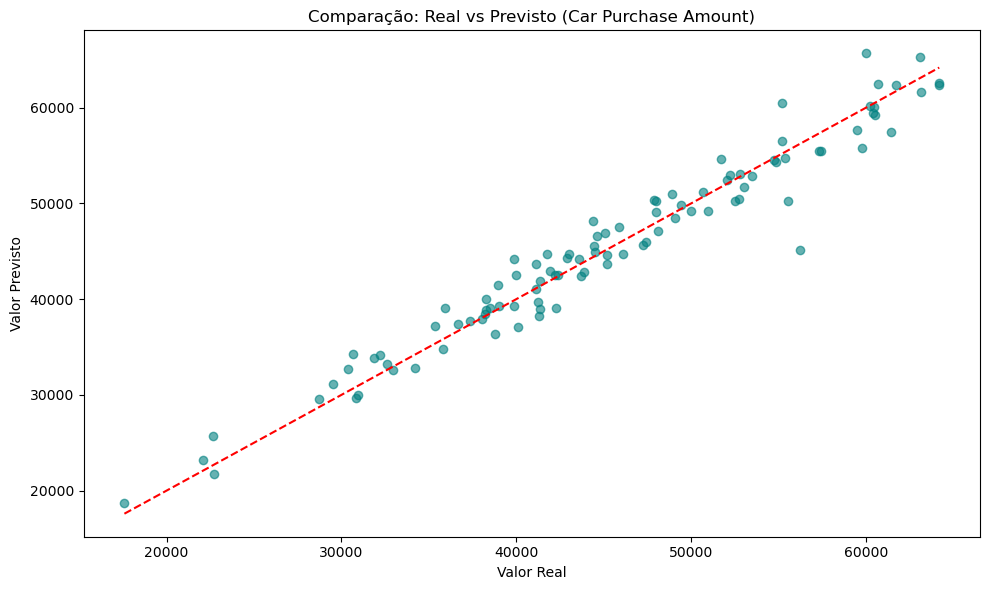

In [322]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.6, color='teal')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Linha ideal
plt.xlabel('Valor Real')
plt.ylabel('Valor Previsto')
plt.title('Comparação: Real vs Previsto (Car Purchase Amount)')
plt.tight_layout()
plt.show()

In [318]:
# avaliação do modelo
mse = mean_squared_error(y_test, y_pred)
rmse = (mse)**(1/2)
r2 = r2_score(y_test, y_pred)

In [319]:
print(f'MSE: {mse:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'R²: {r2:.2f}')

MSE: 5188895.52
RMSE: 2277.91
R²: 0.95


In [320]:
importances = model.feature_importances_
features = X_train.columns
importance_df = pd.DataFrame({'Feature': features, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)


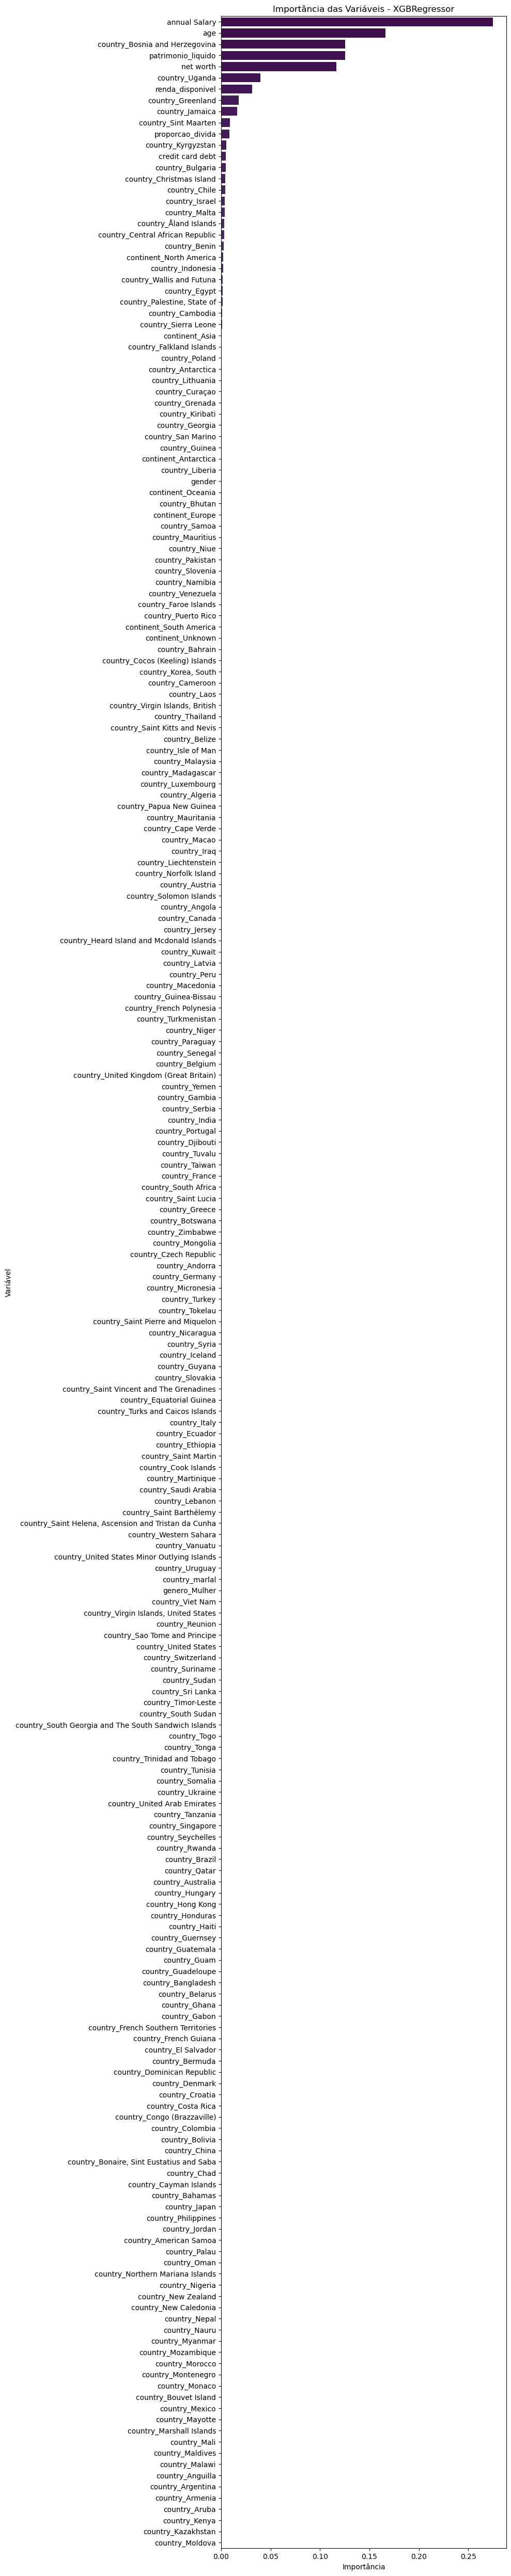

In [324]:
# Plotar
plt.figure(figsize=(10, 50))
sns.barplot(data=importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Importância das Variáveis - XGBRegressor')
plt.xlabel('Importância')
plt.ylabel('Variável')
plt.tight_layout()
plt.show()

## **Clusterização**

In [326]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   customer name         500 non-null    object  
 1   customer e-mail       500 non-null    object  
 2   country               500 non-null    object  
 3   gender                500 non-null    int64   
 4   age                   500 non-null    float64 
 5   annual Salary         500 non-null    float64 
 6   credit card debt      500 non-null    float64 
 7   net worth             500 non-null    float64 
 8   car purchase amount   500 non-null    float64 
 9   faixa_compra          500 non-null    category
 10  genero                500 non-null    object  
 11  continent             500 non-null    object  
 12  renda_disponivel      500 non-null    float64 
 13  proporcao_divida      500 non-null    float64 
 14  patrimonio_liquido    500 non-null    float64 
 15  faixa_

In [327]:
cluster_data = df1[['age', 'annual Salary', 'gender', 'renda_disponivel', 'credit card debt', 'proporcao_divida']].copy()

In [328]:
# Normalização
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)

In [329]:
# Encontrar número ideal de clusters (opcional: Elbow method)
inertia = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(cluster_scaled)
    inertia.append(km.inertia_)

c:\Users\maria\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\maria\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\maria\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
c:\Users\maria\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of

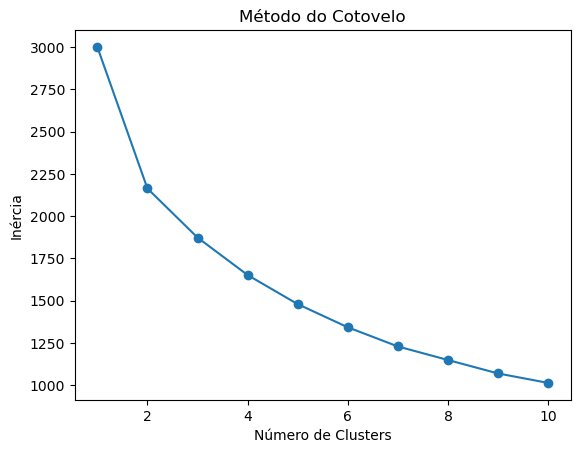

In [330]:
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Método do Cotovelo')
plt.xlabel('Número de Clusters')
plt.ylabel('Inércia')
plt.show()

In [332]:
# Aplicar KMeans com número ideal de clusters
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(cluster_scaled)

# Adicionar ao dataframe original
df1['Cluster'] = clusters

c:\Users\maria\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


In [337]:
print(df1['Cluster'].value_counts())

Cluster
1    255
0    245
Name: count, dtype: int64


In [338]:
df1.select_dtypes(include='number').groupby(df1['Cluster']).mean()


,gender,age,annual Salary,credit card debt,net worth,car purchase amount,renda_disponivel,proporcao_divida,patrimonio_liquido,age_scaled,salary_scaled,purchase_scaled,score_marketing_alvo,Cluster
Cluster,,,,,,,,,,,,,,
0,0.579592,46.160632,54303.064612,11186.710165,423783.435416,39518.785014,43116.354448,0.208089,412596.725251,0.523213,0.428788,0.429842,52.202327,0.0
1,0.435294,46.319538,69644.584211,8090.504055,438866.333865,48716.852081,61554.080156,0.114820,430775.829810,0.526391,0.620557,0.559392,61.355412,1.0


## **Separação dos Perifs**

In [359]:
grupo1 = df1[df1['Cluster'] == 1.0]
grupo2 = df1[df1['Cluster'] == 0.0]

## **Análise Categórica - Grupo 1**

In [355]:
grupo1['faixa_etaria'].value_counts(normalize=True).sort_values(ascending=False).round(2)

faixa_etaria
adulto    0.64
sênior    0.34
jovem     0.02
Name: proportion, dtype: float64

In [356]:
grupo1['faixa_salarial'].value_counts(normalize=True).sort_values(ascending=False).round(2)

faixa_salarial
média      0.98
baixa      0.02
alta       0.00
premium    0.00
Name: proportion, dtype: float64

In [357]:
grupo1['engajamento_previsto'].value_counts(normalize=True).sort_values(ascending=False).round(2)

engajamento_previsto
Médio    0.56
Alto     0.26
Baixo    0.17
Name: proportion, dtype: float64

In [358]:
grupo1['continent'].value_counts(normalize=True).sort_values(ascending=False).round(2)

continent
Asia             0.24
Africa           0.20
Europe           0.18
North America    0.17
Oceania          0.12
South America    0.07
Antarctica       0.02
Name: proportion, dtype: float64

In [354]:
grupo1['faixa_compra'].value_counts(normalize=True).sort_values(ascending=False).round(2)

faixa_compra
40k-50k         0.40
50k-60k         0.26
30k-40k         0.18
Acima de 60k    0.14
20k-30k         0.02
Até 20k         0.00
Name: proportion, dtype: float64

In [353]:
grupo1['country'].value_counts().sort_values(ascending=False).round(2)

country
Saint Barthélemy                                5
Egypt                                           4
Armenia                                         4
Israel                                          4
Laos                                            4
Guam                                            3
Latvia                                          3
Senegal                                         3
Isle of Man                                     3
United Arab Emirates                            3
Maldives                                        3
Marshall Islands                                3
Bouvet Island                                   3
Slovakia                                        3
Macedonia                                       3
China                                           3
Congo (Brazzaville)                             3
Åland Islands                                   3
Bhutan                                          3
Croatia                                   

In [343]:
grupo1.describe()

,gender,age,annual Salary,credit card debt,net worth,car purchase amount,renda_disponivel,proporcao_divida,patrimonio_liquido,age_scaled,salary_scaled,purchase_scaled,score_marketing_alvo,Cluster
count,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.000000,255.0
mean,0.435294,46.319538,69644.584211,8090.504055,438866.333865,48716.852081,61554.080156,0.114820,430775.829810,0.526391,0.620557,0.559392,61.355412,1.0
std,0.496770,7.656806,8735.573159,3135.577495,181817.471293,9503.063110,7571.079383,0.039824,182111.058151,0.153136,0.109195,0.133846,5.748158,0.0
min,0.000000,20.000000,45362.669820,100.000000,20000.000000,22599.458630,42837.677715,0.001419,14911.760983,0.000000,0.317033,0.191542,46.630000,1.0
25%,0.000000,40.938263,64428.335055,6243.925828,303249.518300,41672.365135,56734.643683,0.091318,294060.503670,0.418765,0.555354,0.460174,57.745000,1.0
50%,0.000000,46.520642,69612.012300,8092.475103,441527.014400,47984.420620,60931.395279,0.117472,435379.095557,0.530413,0.620150,0.549076,60.950000,1.0
75%,1.000000,51.339047,74445.404350,10116.418435,557022.418900,55171.181535,65601.564282,0.143550,550435.303991,0.626781,0.680568,0.650298,65.015000,1.0
max,1.000000,65.224881,100000.000000,17452.921790,1000000.000000,80000.000000,87066.778476,0.201155,990125.924673,0.904498,1.000000,1.000000,78.490000,1.0


# **Análise de Clusterização - Grupo 1**

- Faixa Salarial: 40k-60k

- 

- Idade: Média 46,3 anos, com desvio padrão ~7,7 anos. Variável com idade mínima 20 e máxima 65 anos, grupo adulto maduro.

- Salário Anual Médio: R$ 69.644, com desvio padrão de R$ 8.735, indicando variação moderada. Máximo atinge R$ 100k

- Divida no cartão: R$ 8.090, com variação significativa (desvio ~3.136). Mínimo muito baixo (R$ 100), máximo alto.

- Patrimônio: R$ 438.866, desvio padrão alto (~R$ 181.817), varia entre R$ 20k e R$ 1 milhão, indicando heterogeneidade.

- Valor de compra de carro: R$ 48.716, varia bastante (desvio ~R$ 9.503), com máximo R$ 80k.

- Renda disponível: R$ 61.554, com variação (desvio ~R$ 7.571), mínima R$ 42.837 e máxima R$ 87.066

- Dívida: Proporção média da dívida em relação à renda é baixa (~11,5%), com variação pequena (desvio ~0,04).


Resumo: 
Grupo com perfil financeiramente saudável:
Salário anual e renda disponível altos, patrimônio elevado e proporção baixa de dívida em relação à renda.

Idade concentrada em adultos maduros (~40-55 anos na maior parte).

Dívida no cartão relativamente controlada.

Maior investimento em compra de carro, sugerindo maior poder aquisitivo.

Score de marketing mais alto, indica maior propensão à resposta a campanhas.

Gênero: aproximadamente 43,5% são do gênero codificado como 1 (depende da sua codificação).

Cluster 1: Pessoas com maior salário, maior renda disponível, menor proporção de dívida, patrimônio e gastos maiores com compra de carro. Também possuem um score de marketing mais alto. Talvez seja um grupo mais “financeiramente saudável” ou com maior poder aquisitivo.

In [342]:
grupo2 = df1[df1['Cluster'] == 0.0]

Cluster 0: Pessoas com salário e renda menor, maior dívida relativa, e gastos menores com carro. Pode representar um grupo com menos capacidade financeira ou mais endividado.